In [1]:
# === 1. Imports & Setup ===
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from pathlib import Path

# --- Setup ---
DATA_DIR = Path("../data/ta-data")

def load_ticker(ticker: str) -> pd.DataFrame:
    """Load TA-enriched CSV for a given ticker."""
    csv_path = DATA_DIR / f"{ticker}.csv"
    df = pd.read_csv(csv_path, parse_dates=["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    return df

# Default: NG.L
ticker = "NG.L"
df = load_ticker(ticker)
df.index = df["Date"]
# --- Filter to last 10 years ---
cutoff_date = pd.Timestamp("2024-10-15")
df = df[df["Date"] >= cutoff_date].reset_index(drop=True)
df.index = df["Date"]
window = len(df)

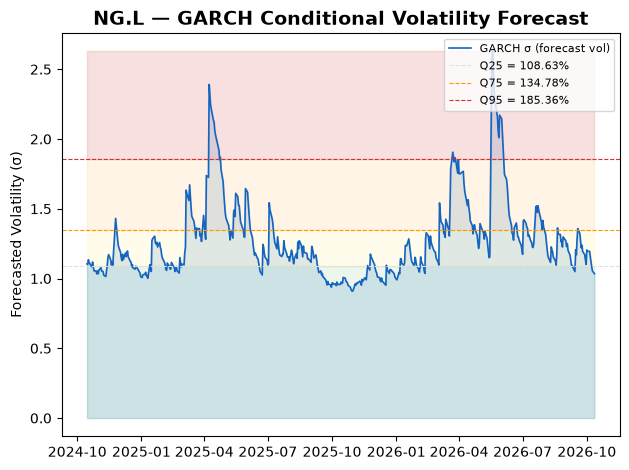

Volatility summary (last 504 bars):
  Q25 (low):   108.6328%
  Median:      119.0745%
  Q75 (med):   134.7764%
  Q95 (high):  185.3595%
  Current:     103.4870%


In [2]:
# === 2. GARCH Volatility Regime ===
# GARCH forecasts future volatility — high vol clusters, low vol clusters.
# Used as a confidence filter for trading signals.

garch_vol = df["ta_garch_vol"].dropna()

fig, ax = plt.subplots()
ax.plot(df.index, garch_vol, color="#1565c0", linewidth=1.2, label="GARCH σ (forecast vol)")
ax.fill_between(df.index, garch_vol, alpha=0.15, color="#1565c0")

# Shade volatility regimes
q25, q75, q95 = garch_vol.quantile([0.25, 0.75, 0.95])
ax.axhline(q25, color="#e0e0e0", linestyle="--", linewidth=0.8, label=f"Q25 = {q25:.2%}")
ax.axhline(q75, color="#ff9800", linestyle="--", linewidth=0.8, label=f"Q75 = {q75:.2%}")
ax.axhline(q95, color="#d32f2f", linestyle="--", linewidth=0.8, label=f"Q95 = {q95:.2%}")

ax.fill_between(df.index, 0, q25, alpha=0.1, color="#4caf50")
ax.fill_between(df.index, q25, q75, alpha=0.1, color="#ffeb3b")
ax.fill_between(df.index, q75, q95, alpha=0.1, color="#ff9800")
ax.fill_between(df.index, q95, garch_vol.max(), alpha=0.15, color="#d32f2f")

ax.legend(loc="upper right", fontsize=8)
ax.set_title(f"{ticker} — GARCH Conditional Volatility Forecast", fontsize=14, fontweight="bold")
ax.set_ylabel("Forecasted Volatility (σ)")
plt.tight_layout()
plt.show()

print(f"Volatility summary (last {window} bars):")
print(f"  Q25 (low):   {q25:.4%}")
print(f"  Median:      {garch_vol.median():.4%}")
print(f"  Q75 (med):   {q75:.4%}")
print(f"  Q95 (high):  {q95:.4%}")
print(f"  Current:     {df['ta_garch_vol'].iloc[-1]:.4%}")

In [3]:
# === 3. GARCH Regime Classification ===
# Classify each bar into Low / Medium / High / Extreme volatility regime
# based on GARCH percentile thresholds.

vol = df["ta_garch_vol"]
q25, q75, q95 = vol.dropna().quantile([0.25, 0.75, 0.95])

def classify_vol(v):
    if pd.isna(v):
        return "Unknown"
    elif v < q25:
        return "Low"
    elif v < q75:
        return "Medium"
    elif v < q95:
        return "High"
    else:
        return "Extreme"

df["ta_garch_regime"] = vol.apply(classify_vol)

# Count distribution
regime_counts = df["ta_garch_regime"].value_counts().sort_index()
print("GARCH Regime Distribution:")
for regime, count in regime_counts.items():
    bar = "█" * (count // 5)
    print(f"  {regime:10s}: {count:4d} ({count/len(df)*100:5.1f}%) {bar}")

# Current regime
current_regime = df["ta_garch_regime"].iloc[-1]
print(f"\nCurrent GARCH regime: {current_regime} ({vol.iloc[-1]:.4%})")

# Trading implication
implications = {
    "Low":    "Good for trend following & breakouts",
    "Medium": "Neutral — standard position sizing",
    "High":   "Reduce position size, watch for whipsaws",
    "Extreme": "Avoid new trades, preserve capital",
    "Unknown": "Insufficient data",
}
print(f"Implication: {implications.get(current_regime, 'N/A')}")

GARCH Regime Distribution:
  Extreme   :   26 (  5.2%) █████
  High      :  100 ( 19.8%) ████████████████████
  Low       :  126 ( 25.0%) █████████████████████████
  Medium    :  252 ( 50.0%) ██████████████████████████████████████████████████

Current GARCH regime: Low (103.4870%)
Implication: Good for trend following & breakouts


/tmp/ipykernel_29734/4120391122.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(loc="upper left", fontsize=8)
/tmp/ipykernel_29734/4120391122.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


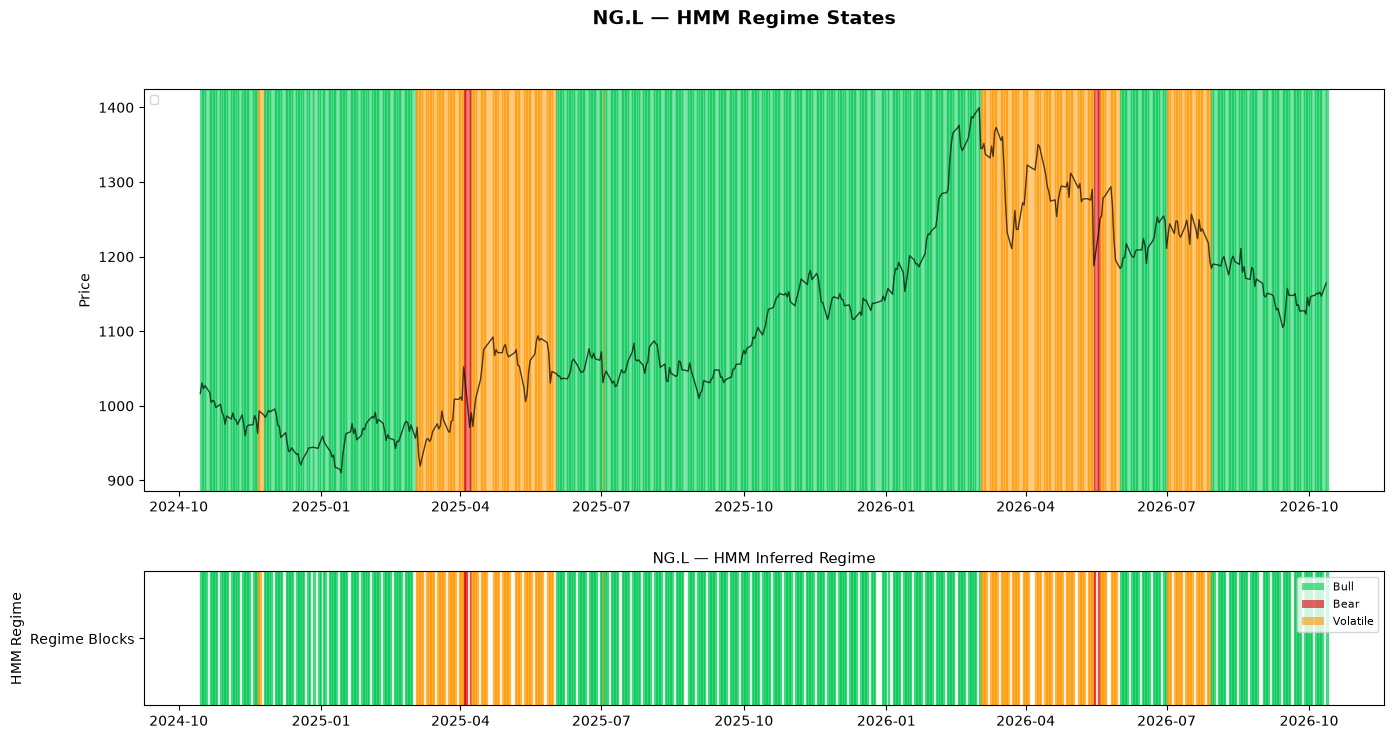

HMM State Distribution:
  Bull       (state 0):  359 ( 71.2%)
  Bear       (state 1):    5 (  1.0%)
  Volatile   (state 2):  140 ( 27.8%)

Current HMM state: Bull (0)


In [4]:
# === 4. HMM Regime States ===
# Hidden Markov Model infers hidden market states:
#   0 = Bull  (highest mean return)
#   1 = Bear  (lowest mean return)
#   2 = Volatile (middle mean return)

hmm = df["ta_hmm_regime"]

# Map state codes to names
state_names = {0: "Bull", 1: "Bear", 2: "Volatile"}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), height_ratios=[3, 1], gridspec_kw={"hspace": 0.3})
fig.suptitle(f"{ticker} — HMM Regime States", fontsize=14, fontweight="bold")

# Plot 1: regime as colored blocks
state_colors = {0: "#00c853", 1: "#d50000", 2: "#ff9800"}
for i in range(len(df)):
    regime = hmm.iloc[i]
    if pd.notna(regime):
        ax1.axvspan(df.index[i], df.index[i + 1] if i + 1 < len(df) else df.index[i] + pd.Timedelta(days=1),
                     color=state_colors.get(int(regime), "#e0e0e0"), alpha=0.5)

ax1.plot(df.index, df["Close"], color="black", linewidth=1, alpha=0.7)
ax1.legend(loc="upper left", fontsize=8)
ax1.set_ylabel("Price")

# Plot 2: regime bar
regime_display = hmm.map(lambda x: state_names.get(int(x), "Unknown") if pd.notna(x) else "Unknown")
for i, (idx, regime_name) in enumerate(regime_display.items()):
    ax2.axvspan(idx, idx + pd.Timedelta(days=1), color=state_colors.get(int(hmm.iloc[i]), "#e0e0e0") if pd.notna(hmm.iloc[i]) else "#e0e0e0", alpha=0.6)

ax2.set_yticks([0.5])
ax2.set_yticklabels(["Regime Blocks"])
ax2.set_ylabel("HMM Regime")

# Custom legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor="#00c853", alpha=0.6, label="Bull"),
                   Patch(facecolor="#d50000", alpha=0.6, label="Bear"),
                   Patch(facecolor="#ff9800", alpha=0.6, label="Volatile")]
ax2.legend(handles=legend_elements, loc="upper right", fontsize=8)
ax2.set_title(f"{ticker} — HMM Inferred Regime", fontsize=11)

plt.tight_layout()
plt.show()

# State distribution
dist = df["ta_hmm_regime"].value_counts().sort_index()
print("HMM State Distribution:")
for state, count in dist.items():
    name = state_names.get(int(state), f"State {state}")
    print(f"  {name:10s} (state {int(state)}): {count:4d} ({count/len(df)*100:5.1f}%)")

current_state = int(hmm.iloc[-1]) if pd.notna(hmm.iloc[-1]) else None
print(f"\nCurrent HMM state: {state_names.get(current_state, 'Unknown')} ({current_state})")

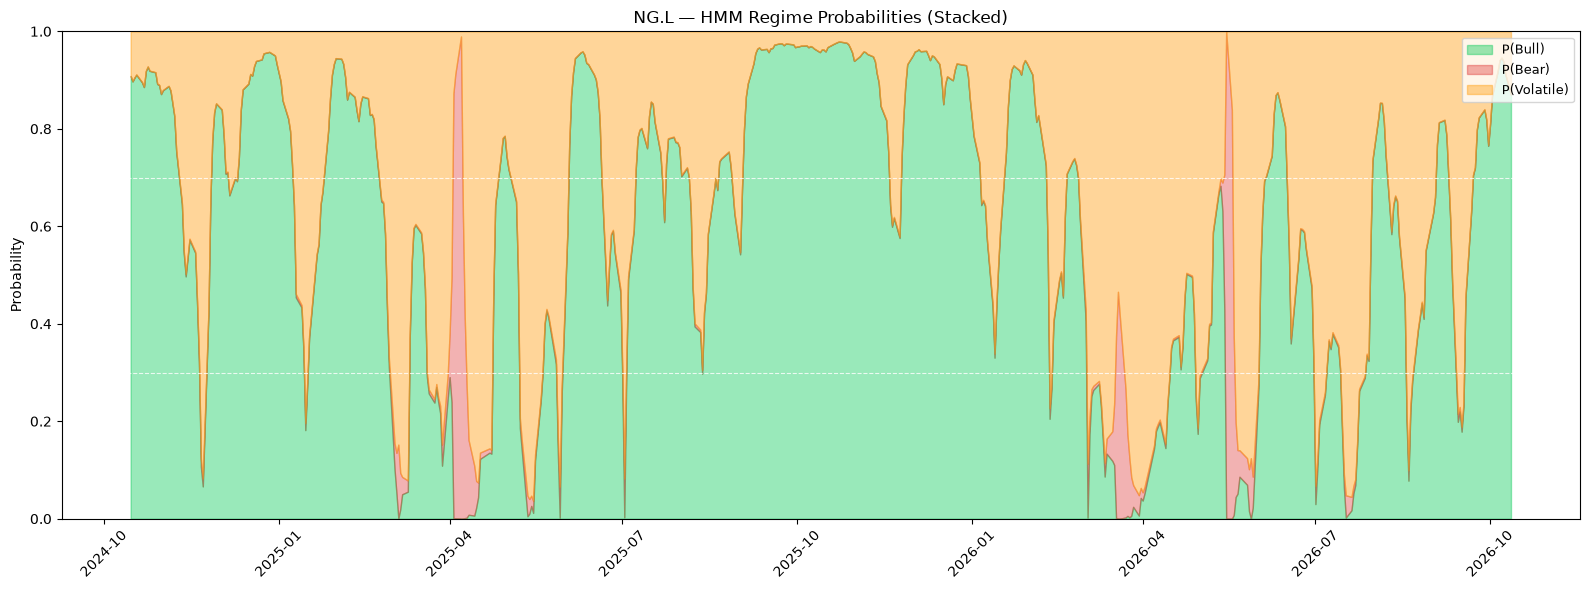

HMM Confidence Levels:
  High (>70%):   344 ( 68.3%)
  Medium (40-70%):  160 ( 31.7%)
  Low (≤40%):    0 (  0.0%)

Current probabilities:
  Bull      : 86.94% ███████████████████████████████████████████
  Bear      : 0.13% 
  Volatile  : 12.93% ██████


In [5]:
# === 5. HMM State Probabilities ===
# Shows the probability distribution across all 3 states for each bar.
# High-confidence regime = one state dominates (>70%).
# Low-confidence = probabilities are spread out.

fig, ax = plt.subplots(figsize=(16, 6))
ax.fill_between(df.index, df["ta_hmm_regime_prob_0"], color="#00c853", alpha=0.4, label="P(Bull)")
ax.fill_between(df.index, df["ta_hmm_regime_prob_0"], df["ta_hmm_regime_prob_0"] + df["ta_hmm_regime_prob_1"],
                 color="#d50000", alpha=0.3, label="P(Bear)")
ax.fill_between(df.index, df["ta_hmm_regime_prob_0"] + df["ta_hmm_regime_prob_1"], 1.0,
                 color="#ff9800", alpha=0.4, label="P(Volatile)")

ax.axhline(0.7, color="white", linestyle="--", linewidth=0.8, alpha=0.8)
ax.axhline(0.3, color="white", linestyle="--", linewidth=0.8, alpha=0.8)

ax.set_ylabel("Probability")
ax.set_ylim(0, 1)
ax.legend(loc="upper right", fontsize=9)
ax.set_title(f"{ticker} — HMM Regime Probabilities (Stacked)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Confidence analysis
prob_max = df[["ta_hmm_regime_prob_0", "ta_hmm_regime_prob_1", "ta_hmm_regime_prob_2"]].max(axis=1)
high_conf = (prob_max > 0.7).sum()
med_conf = ((prob_max > 0.4) & (prob_max <= 0.7)).sum()
low_conf = (prob_max <= 0.4).sum()

print("HMM Confidence Levels:")
print(f"  High (>70%):  {high_conf:4d} ({high_conf/len(df)*100:5.1f}%)")
print(f"  Medium (40-70%): {med_conf:4d} ({med_conf/len(df)*100:5.1f}%)")
print(f"  Low (≤40%): {low_conf:4d} ({low_conf/len(df)*100:5.1f}%)")

current_probs = {
    "Bull": df["ta_hmm_regime_prob_0"].iloc[-1],
    "Bear": df["ta_hmm_regime_prob_1"].iloc[-1],
    "Volatile": df["ta_hmm_regime_prob_2"].iloc[-1],
}
print(f"\nCurrent probabilities:")
for state, prob in current_probs.items():
    bar = "█" * int(prob * 50)
    print(f"  {state:10s}: {prob:.2%} {bar}")

In [6]:
# === 6. Log Returns with Regime Overlay ===
# Visualize how log returns behave across different HMM states.
# Bull = positive drift, Bear = negative drift, Volatile = wide swings.

log_ret = df["ta_log_return"].dropna()
hmm = df["ta_hmm_regime"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), height_ratios=[3, 2], gridspec_kw={"hspace": 0.3})
fig.suptitle(f"{ticker} — Log Returns by HMM Regime", fontsize=14, fontweight="bold")

# Plot 1: close with regime shading
state_colors = {0: "#00c853", 1: "#d50000", 2: "#ff9800"}
for i in range(len(df)):
    regime = hmm.iloc[i]
    if pd.notna(regime):
        end_idx = min(i + 1, len(df) - 1)
        ax1.axvspan(df.index[i], df.index[end_idx], color=state_colors.get(int(regime), "#e0e0e0"), alpha=0.2)

ax1.plot(df.index, df["Close"], color="black", linewidth=1, alpha=0.7)
ax1.set_ylabel("Price")
ax1.set_title(f"{ticker} — Price with HMM Regime Background")

# Plot 2: log returns colored by HMM state
for state, color in state_colors.items():
    mask = (hmm == state) & (hmm.notna())
    ax2.bar(df.index[mask], log_ret[mask], width=0.5, color=color, alpha=0.5, label=state)

ax2.axhline(0, color="black", linewidth=0.5)
ax2.legend(loc="upper right", fontsize=8)
ax2.set_ylabel("Log Return")
ax2.set_title("Log Returns Colored by HMM State")

plt.tight_layout()
plt.show()

# Summary stats by state
print("Mean Log Return by HMM State:")
for state, name in [(0, "Bull"), (1, "Bear"), (2, "Volatile")]:
    mask = (hmm == state) & (log_ret.notna())
    if mask.sum() > 0:
        mean_ret = log_ret[mask].mean()
        std_ret = log_ret[mask].std()
        print(f"  {name:10s}: mean={mean_ret:+.4%}, std={std_ret:.4%}, n={mask.sum()}")

KeyError: 'ta_log_return'

In [ ]:
# === 7. MASTER DASHBOARD: All regime indicators combined ===
fig = plt.figure(figsize=(18, 16))
gs = fig.add_gridspec(5, 1, height_ratios=[3, 1.5, 2, 1.5, 1.2], hspace=0.4)

# ---- Row 0: Price with HMM regime shading ----
ax_price = fig.add_subplot(gs[0])
state_colors = {0: "#00c853", 1: "#d50000", 2: "#ff9800"}
hmm = df["ta_hmm_regime"]
for i in range(len(df)):
    regime = hmm.iloc[i]
    if pd.notna(regime):
        end_idx = min(i + 1, len(df) - 1)
        ax_price.axvspan(df.index[i], df.index[end_idx], color=state_colors.get(int(regime), "#e0e0e0"), alpha=0.15)

ax_price.plot(df.index, df["Close"], color="black", linewidth=1.2, label="Close")
ax_price.legend(loc="upper left", fontsize=8)
ax_price.set_ylabel("Price")
ax_price.set_title(f"{ticker} — Regime Dashboard", fontsize=14, fontweight="bold")

# ---- Row 1: GARCH volatility ----
ax_garch = fig.add_subplot(gs[1])
ax_garch.plot(df.index, df["ta_garch_vol"], color="#1565c0", linewidth=1.2, label="GARCH σ")
ax_garch.fill_between(df.index, df["ta_garch_vol"], alpha=0.2, color="#1565c0")

q25, q75, q95 = df["ta_garch_vol"].dropna().quantile([0.25, 0.75, 0.95])
ax_garch.axhline(q25, color="#4caf50", linestyle="--", linewidth=0.8, alpha=0.7, label=f"Q25={q25:.2%}")
ax_garch.axhline(q75, color="#ff9800", linestyle="--", linewidth=0.8, alpha=0.7, label=f"Q75={q75:.2%}")
ax_garch.axhline(q95, color="#d32f2f", linestyle="--", linewidth=0.8, alpha=0.7, label=f"Q95={q95:.2%}")
ax_garch.legend(loc="upper right", fontsize=7)
ax_garch.set_ylabel("Volatility (σ)")
ax_garch.set_title("GARCH Volatility Forecast", fontsize=10)

# ---- Row 2: HMM probabilities ----
ax_probs = fig.add_subplot(gs[2])
ax_probs.fill_between(df.index, df["ta_hmm_regime_prob_0"], color="#00c853", alpha=0.4, label="P(Bull)")
ax_probs.fill_between(df.index, df["ta_hmm_regime_prob_0"], df["ta_hmm_regime_prob_0"] + df["ta_hmm_regime_prob_1"],
                       color="#d50000", alpha=0.3, label="P(Bear)")
ax_probs.fill_between(df.index, df["ta_hmm_regime_prob_0"] + df["ta_hmm_regime_prob_1"], 1.0,
                       color="#ff9800", alpha=0.4, label="P(Volatile)")
ax_probs.axhline(0.7, color="gray", linestyle="--", linewidth=0.5, alpha=0.5)
ax_probs.set_ylim(0, 1)
ax_probs.set_ylabel("Probability")
ax_probs.legend(loc="upper right", fontsize=8)
ax_probs.set_title("HMM Regime Probabilities", fontsize=10)

# ---- Row 3: HMM regime blocks ----
ax_hmm = fig.add_subplot(gs[3])
for i in range(len(df)):
    regime = hmm.iloc[i]
    if pd.notna(regime):
        end_idx = min(i + 1, len(df) - 1)
        ax_hmm.axvspan(df.index[i], df.index[end_idx], color=state_colors.get(int(regime), "#e0e0e0"), alpha=0.5)
ax_hmm.set_yticks([0.5])
ax_hmm.set_yticklabels([""])
ax_hmm.set_ylabel("Regime")
ax_hmm.set_title("HMM Inferred State (Bull/Bear/Volatile)", fontsize=10)

legend_patches = [
    plt.Line2D([0], [0], color="#00c853", alpha=0.5, label="Bull"),
    plt.Line2D([0], [0], color="#d50000", alpha=0.5, label="Bear"),
    plt.Line2D([0], [0], color="#ff9800", alpha=0.5, label="Volatile"),
]
ax_hmm.legend(handles=legend_patches, loc="upper right", fontsize=7)

# ---- Row 4: Summary stats ----
ax_summary = fig.add_subplot(gs[4])
ax_summary.axis("off")

current_garch = df["ta_garch_vol"].iloc[-1]
current_hmm = int(df["ta_hmm_regime"].iloc[-1]) if pd.notna(df["ta_hmm_regime"].iloc[-1]) else None
hmm_names = {0: "Bull", 1: "Bear", 2: "Volatile"}

prob_bull = df["ta_hmm_regime_prob_0"].iloc[-1]
prob_bear = df["ta_hmm_regime_prob_1"].iloc[-1]
prob_vol = df["ta_hmm_regime_prob_2"].iloc[-1]

q25, q75, q95 = df["ta_garch_vol"].dropna().quantile([0.25, 0.75, 0.95])

if current_garch < q25:
    vol_label = "LOW"
    vol_icon = "🟢"
elif current_garch < q75:
    vol_label = "MEDIUM"
    vol_icon = "🟡"
elif current_garch < q95:
    vol_label = "HIGH"
    vol_icon = "🟠"
else:
    vol_label = "EXTREME"
    vol_icon = "🔴"

summary_text = (
    f"📊 Regime Summary (last {window} bars):\n"
    f"GARCH Volatility: {vol_icon} {vol_label} ({current_garch:.2%})\n"
    f"HMM State: {hmm_names.get(current_hmm, '?')} ({current_hmm})\n"
    f"HMM Probabilities: Bull={prob_bull:.1%} | Bear={prob_bear:.1%} | Volatile={prob_vol:.1%}\n"
    f"Volatility Thresholds: Q25={q25:.2%} | Q75={q75:.2%} | Q95={q95:.2%}\n"
    f"Implication: {'Favorable for trend following (low vol, clear regime)' if vol_label in ('LOW', 'MEDIUM') and current_hmm in (0, 2) else 'Caution advised (high vol or mixed regime)' if vol_label in ('HIGH', 'EXTREME') else 'Monitor closely (neutral conditions)'}"
)

ax_summary.text(0.02, 0.5, summary_text, fontsize=10, family="monospace",
                verticalalignment="center",
                bbox=dict(boxstyle="round,pad=0.5", facecolor="#f5f5f5", edgecolor="#999"))

plt.suptitle(f"{ticker} — Complete Regime Dashboard ({window} bars)", fontsize=15, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

plt.savefig("regime_dashboard.png", dpi=150, bbox_inches="tight")
print(f"Dashboard saved — {window} bars, {ticker}")